In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')


In [2]:
data = pd.read_csv('../raw_data/bank_transactions.csv')

In [3]:
# show all columns
pd.set_option('display.max_columns', None)

In [4]:
data.columns

Index(['TransactionID', 'CustomerID', 'CustomerDOB', 'CustGender',
       'CustLocation', 'CustAccountBalance', 'TransactionDate',
       'TransactionTime', 'TransactionAmount (INR)'],
      dtype='str')

In [5]:
data

,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR)
0,T1,C5841053,10/1/94,F,JAMSHEDPUR,17819.05,2/8/16,143207,25.0
1,T2,C2142763,4/4/57,M,JHAJJAR,2270.69,2/8/16,141858,27999.0
2,T3,C4417068,26/11/96,F,MUMBAI,17874.44,2/8/16,142712,459.0
3,T4,C5342380,14/9/73,F,MUMBAI,866503.21,2/8/16,142714,2060.0
4,T5,C9031234,24/3/88,F,NAVI MUMBAI,6714.43,2/8/16,181156,1762.5
...,...,...,...,...,...,...,...,...,...
1048562,T1048563,C8020229,8/4/90,M,NEW DELHI,7635.19,18/9/16,184824,799.0
1048563,T1048564,C6459278,20/2/92,M,NASHIK,27311.42,18/9/16,183734,460.0
1048564,T1048565,C6412354,18/5/89,M,HYDERABAD,221757.06,18/9/16,183313,770.0
1048565,T1048566,C6420483,30/8/78,M,VISAKHAPATNAM,10117.87,18/9/16,184706,1000.0


In [6]:
# Columns i need
COLUMNS = ['CustomerID', 'CustomerDOB', 'CustGender', 'CustLocation','CustAccountBalance', 'TransactionDate', 'TransactionTime', 'TransactionAmount (INR)']

- Assigning a function to clean the data

In [7]:
def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    """Clean the data by removing duplicates and handling missing values."""
    print("Cleaning data started...")

    # filtering columns
    df = df[COLUMNS]
    print("Columns filtered.")

    # rename columns
    df = df.rename(columns={
        'CustomerID': 'Customer_ID',
        'CustomerDOB': 'Customer_Date_of_Birth',
        'CustGender': 'Gender',
        'CustLocation': 'Location',
        'CustAccountBalance': 'Account_Balance',
        'TransactionDate': 'Transaction_Date',
        'TransactionTime': 'Transaction_Time',
        'TransactionAmount (INR)': 'Transaction_Amount_INR'
    })
    print("Columns renamed successfully.")

    # remove duplicates
    df = df.drop_duplicates()
    print("Duplicates removed successfully.")
    
    # handle missing values
    df = df.dropna()
    print("Missing values dropped")

    # remove placeholder date of birth
    df = df[df['Customer_Date_of_Birth'] != '1/1/1800']

    # convert date columns to datetime (dates are day/month/2-digit-year)
    for col in ['Customer_Date_of_Birth', 'Transaction_Date']:
        df[col] = pd.to_datetime(df[col], format='%d/%m/%y')

    # 2-digit years like 57 are parsed as 2057 -> shift them back to the 1900s
    dob = df['Customer_Date_of_Birth']
    df['Customer_Date_of_Birth'] = dob.where(dob <= df['Transaction_Date'], dob - pd.DateOffset(years=100))
    print("Date columns converted to datetime.")

    # age at the time of the transaction, not today
    df = df.assign(Age=(df['Transaction_Date'] - df['Customer_Date_of_Birth']).dt.days // 365)

    # remove age outliers
    df = df[df["Age"].between(0, 100)]
    print("Age outliers removed successfully.")
    print("Data cleaning completed.")

    return df


In [8]:
cleaned_data = clean_data(data)

Cleaning data started...
Columns filtered.
Columns renamed successfully.
Duplicates removed successfully.
Missing values dropped
Date columns converted to datetime.
Age outliers removed successfully.
Data cleaning completed.


In [9]:
cleaned_data

,Customer_ID,Customer_Date_of_Birth,Gender,Location,Account_Balance,Transaction_Date,Transaction_Time,Transaction_Amount_INR,Age
0,C5841053,1994-01-10,F,JAMSHEDPUR,17819.05,2016-08-02,143207,25.0,22
1,C2142763,1957-04-04,M,JHAJJAR,2270.69,2016-08-02,141858,27999.0,59
2,C4417068,1996-11-26,F,MUMBAI,17874.44,2016-08-02,142712,459.0,19
3,C5342380,1973-09-14,F,MUMBAI,866503.21,2016-08-02,142714,2060.0,42
4,C9031234,1988-03-24,F,NAVI MUMBAI,6714.43,2016-08-02,181156,1762.5,28
...,...,...,...,...,...,...,...,...,...
1048562,C8020229,1990-04-08,M,NEW DELHI,7635.19,2016-09-18,184824,799.0,26
1048563,C6459278,1992-02-20,M,NASHIK,27311.42,2016-09-18,183734,460.0,24
1048564,C6412354,1989-05-18,M,HYDERABAD,221757.06,2016-09-18,183313,770.0,27
1048565,C6420483,1978-08-30,M,VISAKHAPATNAM,10117.87,2016-09-18,184706,1000.0,38


In [10]:
df = cleaned_data.sample(n=20000, random_state=42)

In [11]:
df

,Customer_ID,Customer_Date_of_Birth,Gender,Location,Account_Balance,Transaction_Date,Transaction_Time,Transaction_Amount_INR,Age
969977,C7115330,1985-11-23,F,AGARTALA,3597.30,2016-09-10,104308,200.00,30
581373,C7640863,1980-10-09,M,PUNE,66375.67,2016-08-27,131008,500.00,35
982905,C8842270,1992-02-01,M,GURGAON,3255.06,2016-09-15,174443,50.00,24
867360,C5550852,1966-08-05,F,DELHI,33977.24,2016-09-08,132715,5574.72,50
600327,C3015160,1981-05-22,F,NEW DELHI,529718.12,2016-08-26,162051,85.00,35
...,...,...,...,...,...,...,...,...,...
1042633,C7013879,1992-12-10,F,MUMBAI,858.65,2016-09-18,130909,897.00,23
181318,C4333348,1984-08-10,M,GUNTUR,215265.57,2016-08-09,84203,6310.00,32
447497,C7583890,1989-01-03,M,MUMBAI,2798.03,2016-08-16,184443,100.86,27
935794,C2232177,1987-11-04,M,BANGALORE,22600.07,2016-09-11,142147,89.00,28


- Create Bands

In [12]:
bins = [0, 17, 25, 35, 45, 55, 100]
labels = ["<18", "18-25", "26-35", "36-45", "46-55", "56+"]

df["Age_Groups"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df

,Customer_ID,Customer_Date_of_Birth,Gender,Location,Account_Balance,Transaction_Date,Transaction_Time,Transaction_Amount_INR,Age,Age_Groups
969977,C7115330,1985-11-23,F,AGARTALA,3597.30,2016-09-10,104308,200.00,30,26-35
581373,C7640863,1980-10-09,M,PUNE,66375.67,2016-08-27,131008,500.00,35,26-35
982905,C8842270,1992-02-01,M,GURGAON,3255.06,2016-09-15,174443,50.00,24,18-25
867360,C5550852,1966-08-05,F,DELHI,33977.24,2016-09-08,132715,5574.72,50,46-55
600327,C3015160,1981-05-22,F,NEW DELHI,529718.12,2016-08-26,162051,85.00,35,26-35
...,...,...,...,...,...,...,...,...,...,...
1042633,C7013879,1992-12-10,F,MUMBAI,858.65,2016-09-18,130909,897.00,23,18-25
181318,C4333348,1984-08-10,M,GUNTUR,215265.57,2016-08-09,84203,6310.00,32,26-35
447497,C7583890,1989-01-03,M,MUMBAI,2798.03,2016-08-16,184443,100.86,27,26-35
935794,C2232177,1987-11-04,M,BANGALORE,22600.07,2016-09-11,142147,89.00,28,26-35


- Month and Year extraction

In [13]:
df["Transaction_Month"] = df["Transaction_Date"].dt.month
df["Transaction_Year"] = df["Transaction_Date"].dt.year

df.tail()

,Customer_ID,Customer_Date_of_Birth,Gender,Location,Account_Balance,Transaction_Date,Transaction_Time,Transaction_Amount_INR,Age,Age_Groups,Transaction_Month,Transaction_Year
1042633,C7013879,1992-12-10,F,MUMBAI,858.65,2016-09-18,130909,897.00,23,18-25,9,2016
181318,C4333348,1984-08-10,M,GUNTUR,215265.57,2016-08-09,84203,6310.00,32,26-35,8,2016
447497,C7583890,1989-01-03,M,MUMBAI,2798.03,2016-08-16,184443,100.86,27,26-35,8,2016
935794,C2232177,1987-11-04,M,BANGALORE,22600.07,2016-09-11,142147,89.00,28,26-35,9,2016
400740,C8626286,1993-09-17,M,SILIGURI,6595.32,2016-08-18,125514,452.64,22,18-25,8,2016


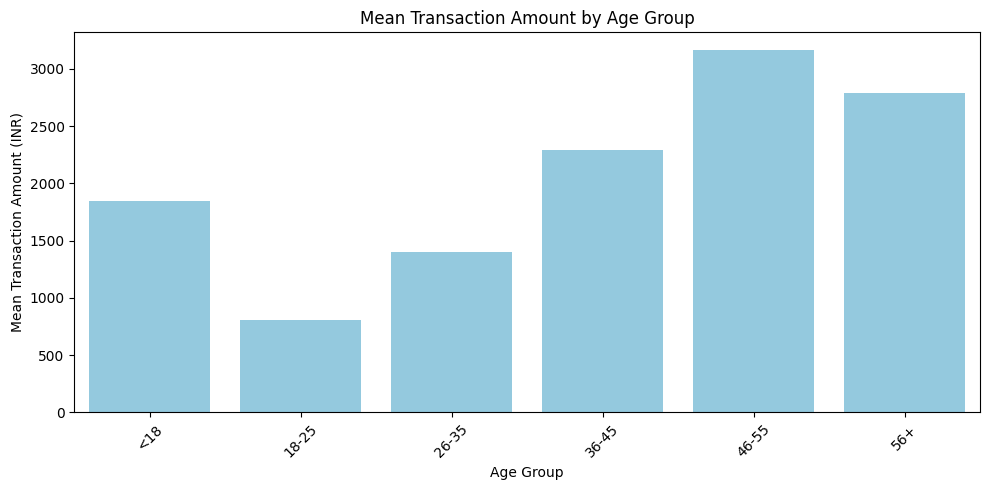

In [14]:
# taking the mean
mean_transactions_by_age = (
    df.groupby("Age_Groups", observed=False)["Transaction_Amount_INR"]
      .mean()
      .reindex(labels)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=mean_transactions_by_age.index,
    y=mean_transactions_by_age.values,
    color="skyblue",
)

plt.title("Mean Transaction Amount by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Mean Transaction Amount (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- The mean by 56+ is high because of higher amount money spent

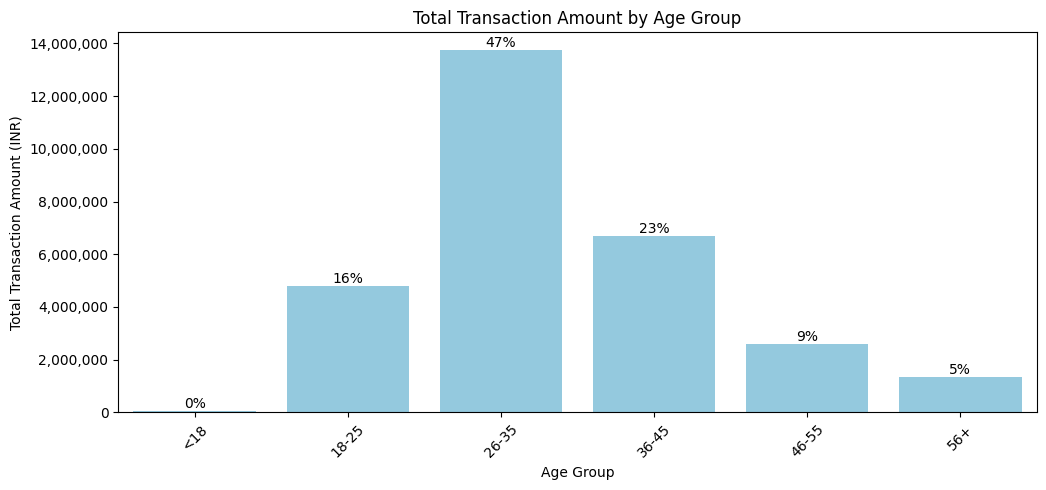

In [15]:
total_transactions_by_age = (
    df.groupby("Age_Groups", observed=False)["Transaction_Amount_INR"]
      .sum()
      .reindex(labels)
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=total_transactions_by_age.index,
    y=total_transactions_by_age.values,
    color="skyblue",
)

# show each group's share of the total spend above its bar
shares = total_transactions_by_age / total_transactions_by_age.sum() * 100
ax.bar_label(ax.containers[0], labels=[f"{s:.0f}%" for s in shares])

plt.title("Total Transaction Amount by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Transaction Amount (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.show()


<Axes: title={'center': 'Total Transaction Amount by Age Group and Gender'}, xlabel='Age_Groups'>

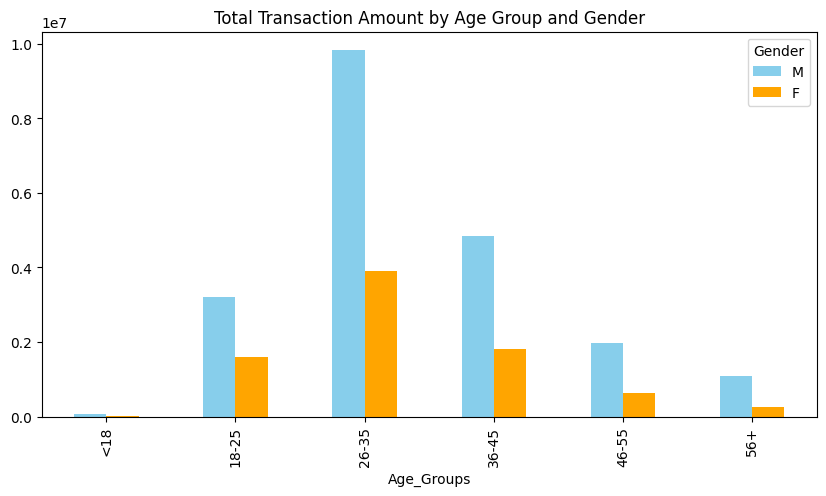

In [16]:
(df.groupby(["Age_Groups", "Gender"], observed=False)["Transaction_Amount_INR"]
   .sum()
   .unstack()
   .reindex(labels)
   .reindex(columns=["M", "F"])
   .plot(
       kind="bar",
       figsize=(10, 5),
       title="Total Transaction Amount by Age Group and Gender",
       color=["skyblue", "orange"]
   ))


- 26–35 are the biggest consumers by volume and total spend, while 56+ make the largest individual purchases.

- I'm gonna work with Top-5 Cities

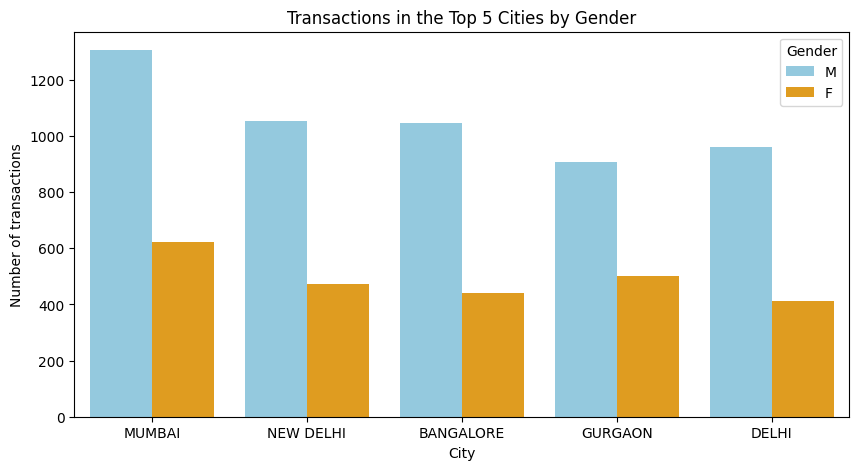

In [17]:
# Top 5 cities with the highest number of transactions
top_cities = df["Location"].value_counts().head(5).index.tolist()

df_top = df[df["Location"].isin(top_cities)]

plt.figure(figsize=(10, 5))
sns.countplot(data=df_top, x="Location", hue="Gender", order=top_cities, palette={"M": "skyblue", "F": "orange"})
plt.title("Transactions in the Top 5 Cities by Gender")
plt.xlabel("City")
plt.ylabel("Number of transactions")
plt.legend(title="Gender")
plt.show()

### Account Balance Analysis

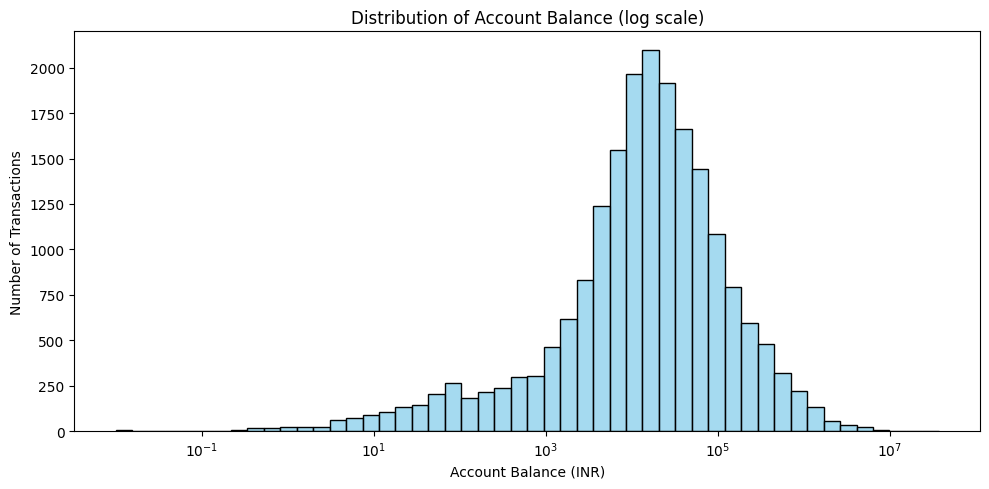

In [18]:
import numpy as np

plt.figure(figsize=(10, 5))
sns.histplot(
    df.loc[df["Account_Balance"] > 0, "Account_Balance"],
    bins=50,
    log_scale=True,
    color="skyblue",
)

plt.title("Distribution of Account Balance (log scale)")
plt.xlabel("Account Balance (INR)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

- The balance is extremely right-skewed, so it is plotted on a log scale. Most customers hold between ~1,000 and ~100,000 INR.

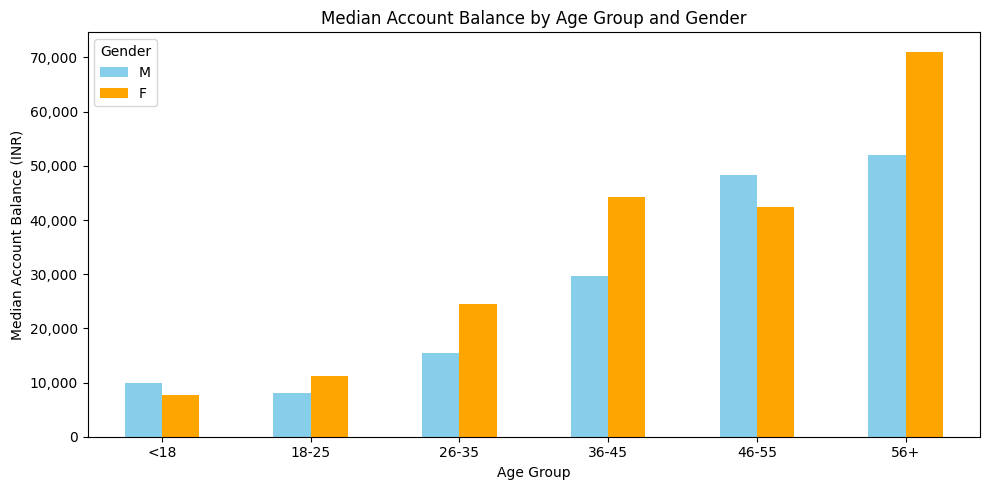

In [19]:
median_balance_by_age_gender = (
    df.groupby(["Age_Groups", "Gender"], observed=False)["Account_Balance"]
      .median()
      .unstack()
      .reindex(labels)
      .reindex(columns=["M", "F"])
)

ax = median_balance_by_age_gender.plot(
    kind="bar",
    figsize=(10, 5),
    color=["skyblue", "orange"],
)

plt.title("Median Account Balance by Age Group and Gender")
plt.xlabel("Age Group")
plt.ylabel("Median Account Balance (INR)")
plt.xticks(rotation=0)
plt.legend(title="Gender")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

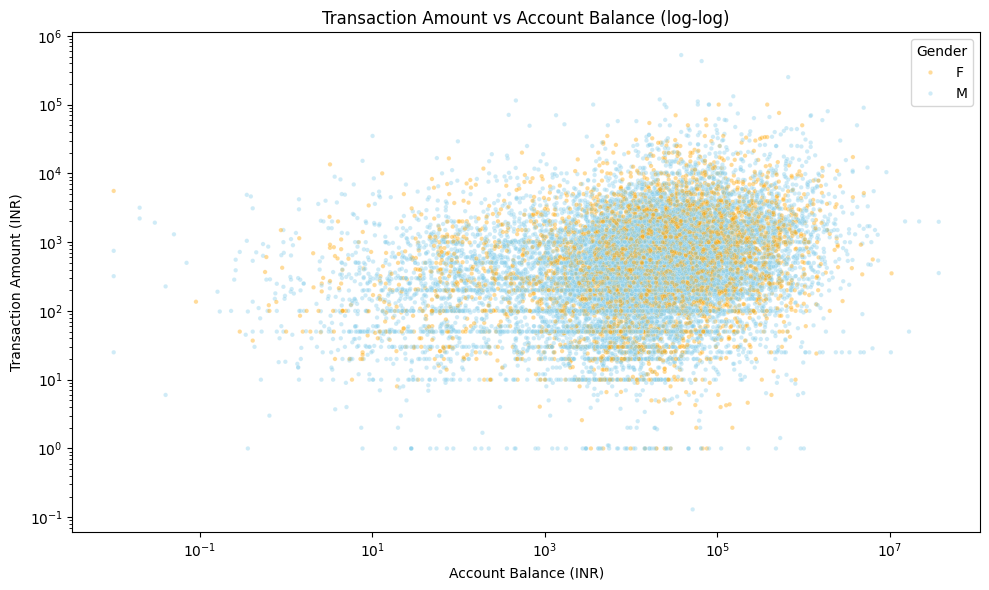

Spearman correlation: 0.274


In [20]:
positive = df[(df["Account_Balance"] > 0) & (df["Transaction_Amount_INR"] > 0)]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=positive,
    x="Account_Balance",
    y="Transaction_Amount_INR",
    hue="Gender",
    palette={"M": "skyblue", "F": "orange"},
    alpha=0.4,
    s=10,
)
plt.xscale("log")
plt.yscale("log")

plt.title("Transaction Amount vs Account Balance (log-log)")
plt.xlabel("Account Balance (INR)")
plt.ylabel("Transaction Amount (INR)")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

# Spearman works on ranks, so it is robust to the heavy skew
print("Spearman correlation:", round(positive["Account_Balance"].corr(positive["Transaction_Amount_INR"], method="spearman"), 3))

- Spend ratio = transaction amount / account balance. It shows how much of their money a customer spends in one transaction.

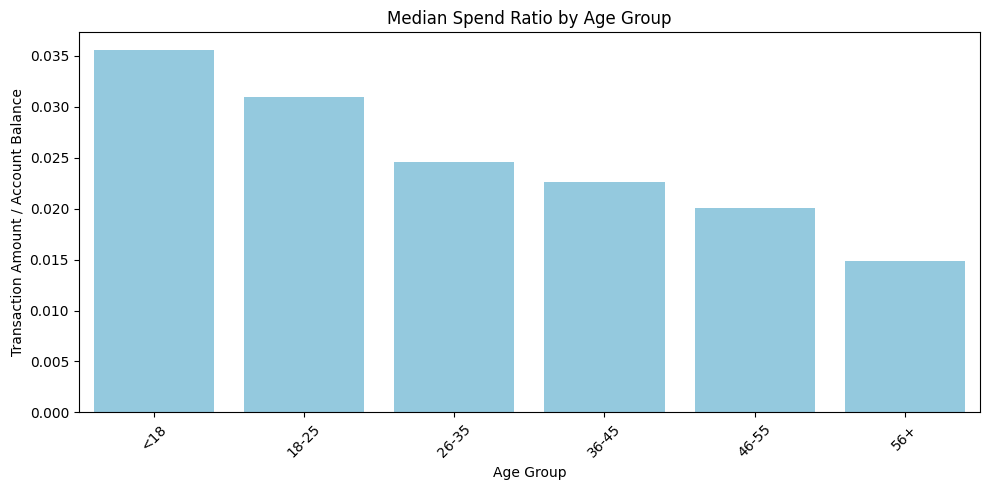

In [21]:
df["Spend_Ratio"] = (df["Transaction_Amount_INR"] / (df["Account_Balance"] + 1)).clip(upper=1)

median_spend_ratio_by_age = (
    df.groupby("Age_Groups", observed=False)["Spend_Ratio"]
      .median()
      .reindex(labels)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=median_spend_ratio_by_age.index,
    y=median_spend_ratio_by_age.values,
    color="skyblue",
)

plt.title("Median Spend Ratio by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Transaction Amount / Account Balance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Time Analysis

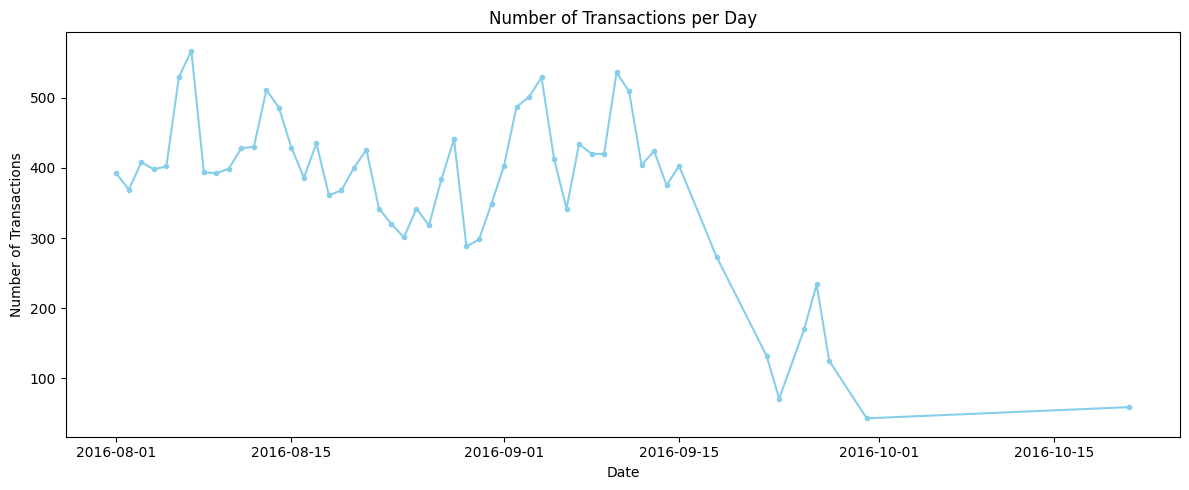

In [22]:
transactions_per_day = df.groupby("Transaction_Date").size()

plt.figure(figsize=(12, 5))
plt.plot(transactions_per_day.index, transactions_per_day.values, color="skyblue", marker="o", markersize=3)

plt.title("Number of Transactions per Day")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

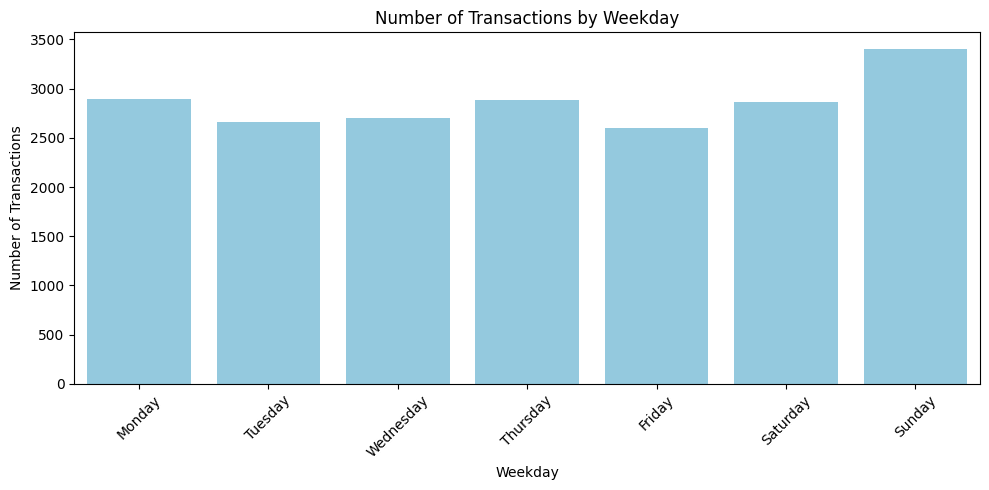

In [23]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["Transaction_Weekday"] = df["Transaction_Date"].dt.day_name()

transactions_by_weekday = df["Transaction_Weekday"].value_counts().reindex(weekday_order)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=transactions_by_weekday.index,
    y=transactions_by_weekday.values,
    color="skyblue",
)

plt.title("Number of Transactions by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

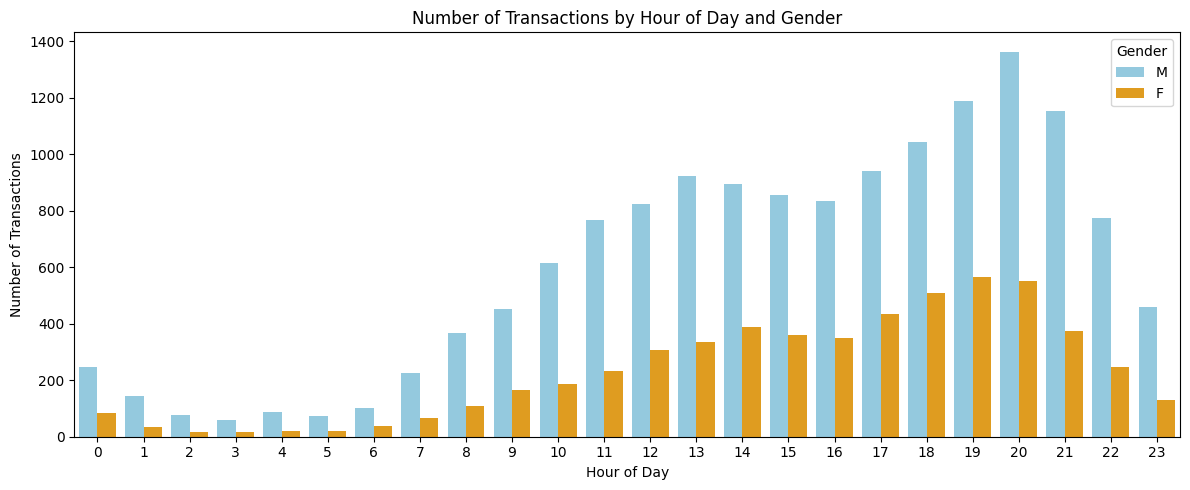

In [24]:
# Transaction_Time is stored as HHMMSS, e.g. 143207 -> 14:32:07
df["Transaction_Hour"] = df["Transaction_Time"] // 10000

plt.figure(figsize=(12, 5))
sns.countplot(data=df, x="Transaction_Hour", hue="Gender", palette={"M": "skyblue", "F": "orange"})

plt.title("Number of Transactions by Hour of Day and Gender")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

### Location Analysis
- Top cities by `total spend` instead of number of transactions

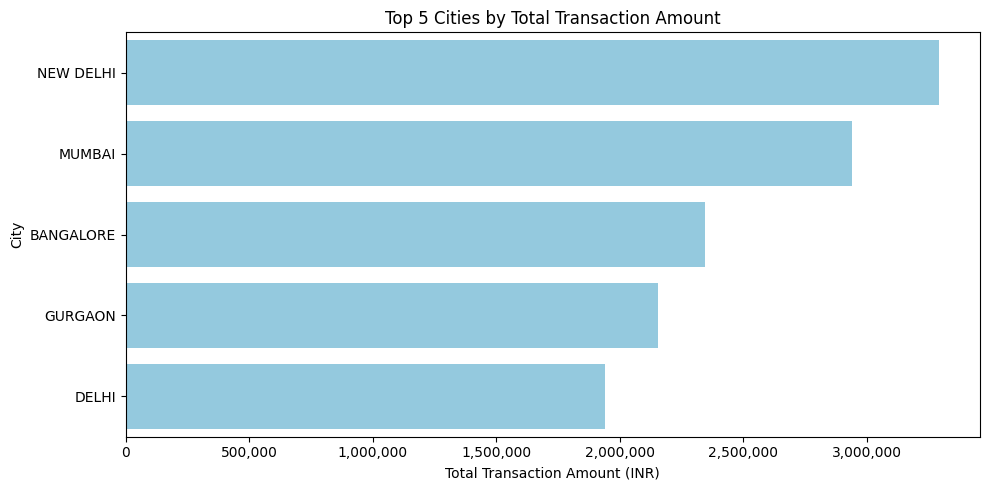

,Transactions,Total_Amount,Median_Amount,Median_Balance
Location,,,,
NEW DELHI,1526,3292748.57,500.0,24382.050
MUMBAI,1929,2938615.07,525.0,22287.920
BANGALORE,1487,2346345.09,425.0,16735.910
GURGAON,1407,2152661.12,499.0,24359.620
DELHI,1374,1939587.47,490.0,15657.695


In [25]:
city_stats = df.groupby("Location").agg(
    Transactions=("Transaction_Amount_INR", "count"),
    Total_Amount=("Transaction_Amount_INR", "sum"),
    Median_Amount=("Transaction_Amount_INR", "median"),
    Median_Balance=("Account_Balance", "median"),
)

top10_by_spend = city_stats.sort_values("Total_Amount", ascending=False).head(5)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=top10_by_spend["Total_Amount"],
    y=top10_by_spend.index,
    color="skyblue",
)

plt.title("Top 5 Cities by Total Transaction Amount")
plt.xlabel("Total Transaction Amount (INR)")
plt.ylabel("City")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

top10_by_spend

### Customer Analysis
- Uses the full `cleaned_data`, because the 20k transaction sample splits customers apart

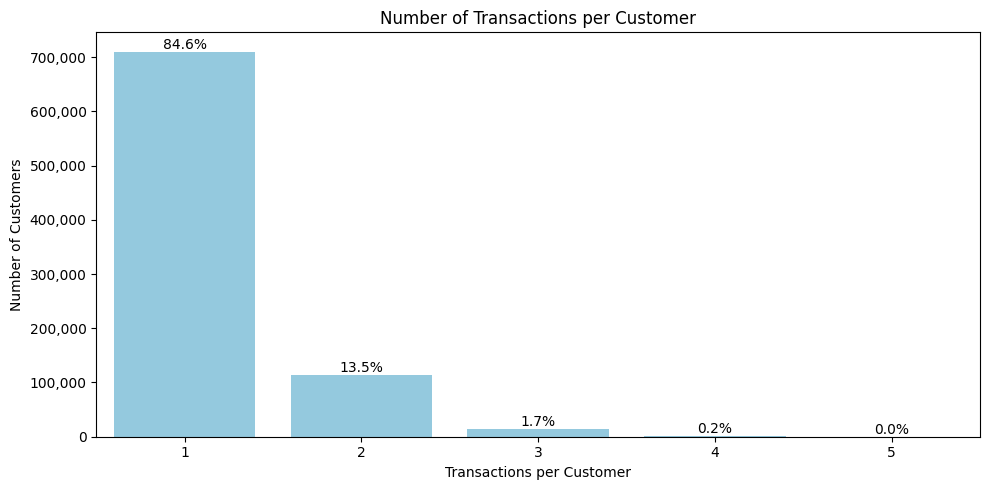

In [26]:
transactions_per_customer = cleaned_data.groupby("Customer_ID").size()
customer_counts = transactions_per_customer.value_counts().sort_index().head(5)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=customer_counts.index,
    y=customer_counts.values,
    color="skyblue",
)

shares = customer_counts / transactions_per_customer.shape[0] * 100
ax.bar_label(ax.containers[0], labels=[f"{s:.1f}%" for s in shares])

plt.title("Number of Transactions per Customer")
plt.xlabel("Transactions per Customer")
plt.ylabel("Number of Customers")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

- Most customers have only one transaction, so frequency and recency won't separate customers well. The clustering will focus on age, balance and spending.

### Preparing the data for KMeans

- KMeans is unsupervised: there is no target `y`. The model finds groups in `X` by itself, and the cluster labels it returns play the role of `y`.
- Clustering is done on customers, not transactions, so the transactions are first aggregated per `CustomerID`.
- `Gender` and `Location` are kept in `customers` to describe the clusters afterwards, but they are not used as features (KMeans works with distances, so categorical columns don't fit well).

In [27]:
customers = cleaned_data.groupby("Customer_ID").agg(
    Age=("Age", "last"),
    Gender=("Gender", "first"),
    Location=("Location", "first"),
    Account_Balance=("Account_Balance", "mean"),
    Total_Amount=("Transaction_Amount_INR", "sum"),
    N_Transactions=("Transaction_Amount_INR", "count"),
)
customers["Spend_Ratio"] = (customers["Total_Amount"] / (customers["Account_Balance"] + 1)).clip(upper=1)

print(customers.shape)
customers.describe()

(839081, 7)


,Age,Account_Balance,Total_Amount,N_Transactions,Spend_Ratio
count,839081.000000,8.390810e+05,8.390810e+05,839081.000000,839081.000000
mean,30.715117,1.058545e+05,1.705564e+03,1.174287,0.164548
std,8.764308,7.862524e+05,6.687656e+03,0.435129,0.299571
min,0.000000,0.000000e+00,0.000000e+00,1.000000,0.000000
25%,25.000000,5.366190e+03,1.980000e+02,1.000000,0.007513
50%,28.000000,1.768220e+04,5.000000e+02,1.000000,0.028805
75%,34.000000,5.723652e+04,1.418000e+03,1.000000,0.124251
max,98.000000,1.150355e+08,1.560035e+06,6.000000,1.000000


- Features: `Age`, `Account_Balance`, `Total_Amount`, `Spend_Ratio`
- `Account_Balance` and `Total_Amount` are very skewed, so `log1p` is applied first. Otherwise a few very rich customers would dominate the distances.

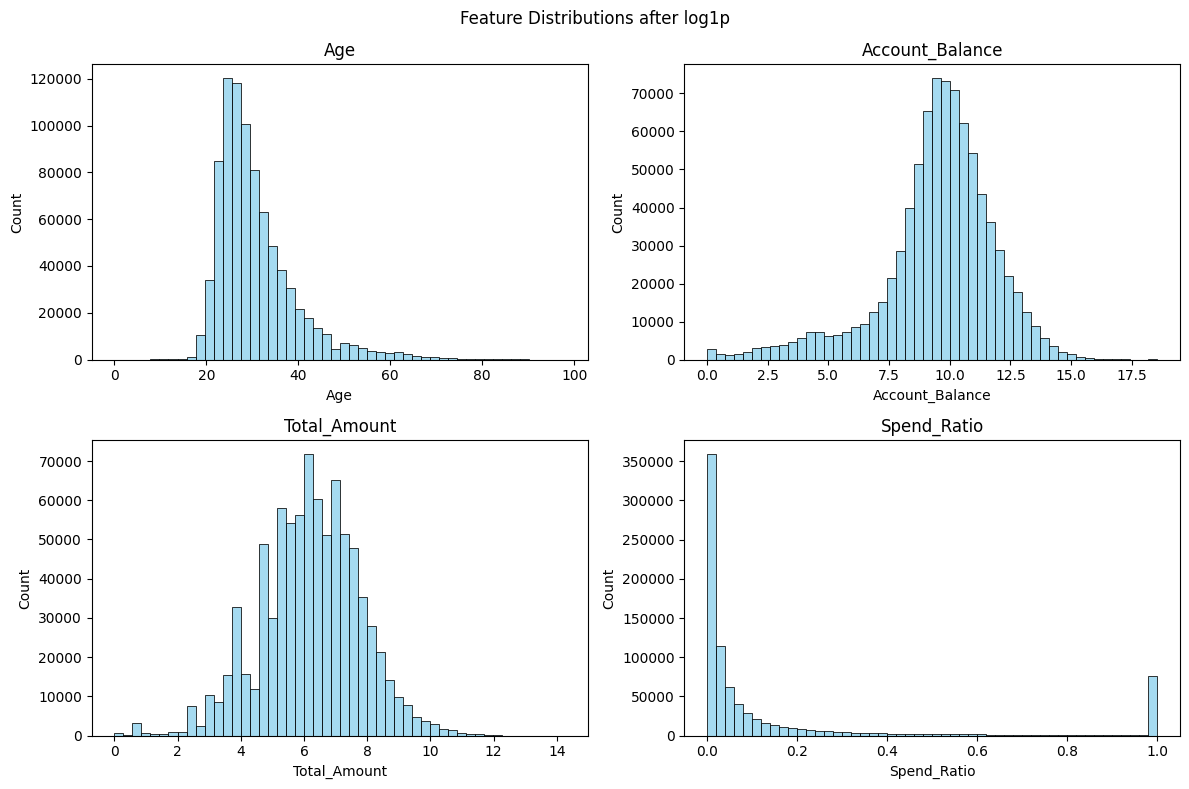

In [28]:
FEATURES = ["Age", "Account_Balance", "Total_Amount", "Spend_Ratio"]

X = customers[FEATURES].copy()
X[["Account_Balance", "Total_Amount"]] = np.log1p(X[["Account_Balance", "Total_Amount"]])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(X[col], bins=50, color="skyblue", ax=ax)
    ax.set_title(col)
plt.suptitle("Feature Distributions after log1p")
plt.tight_layout()
plt.show()

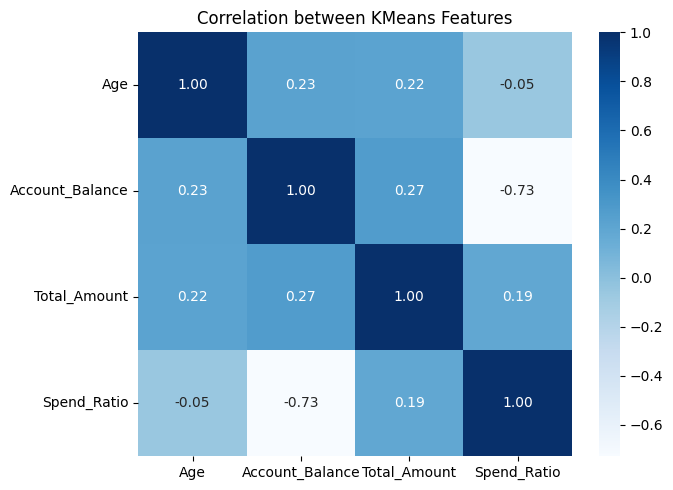

In [29]:
plt.figure(figsize=(7, 5))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlation between KMeans Features")
plt.tight_layout()
plt.show()

- KMeans uses distances, so all features must be on the same scale. `StandardScaler` gives every feature mean 0 and standard deviation 1.

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=FEATURES, index=X.index)

X_scaled.describe().round(2)

,Age,Account_Balance,Total_Amount,Spend_Ratio
count,839081.00,839081.00,839081.00,839081.00
mean,-0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-3.50,-4.00,-3.89,-0.55
25%,-0.65,-0.39,-0.56,-0.52
50%,-0.31,0.11,0.02,-0.45
75%,0.37,0.60,0.67,-0.13
max,7.68,3.80,5.06,2.79


In [31]:
X_scaled.sample(50000, random_state=42)

,Age,Account_Balance,Total_Amount,Spend_Ratio
Customer_ID,,,,
C8288855,-0.766190,0.277183,-2.381374,-0.548019
C1194235,-0.195693,-0.121915,0.136808,-0.351431
C3241125,0.488902,1.116189,0.309944,-0.535591
C3820941,-0.423892,0.329939,-0.630566,-0.529486
C3590039,-0.195693,-0.519432,-0.989745,-0.465301
...,...,...,...,...
C3547083,0.146604,0.712724,0.380290,-0.509267
C4812083,0.831199,-0.324436,0.929948,0.585778
C7712023,-0.994388,-0.268909,-1.002298,-0.503948


In [32]:
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    print(k, round(km.inertia_), round(silhouette_score(X_scaled, km.labels_, sample_size=10000), 3))

2 2230042 0.503
3 1632443 0.305
4 1300555 0.3
5 1162823 0.295
6 1037944 0.245
7 942627 0.247
8 871621 0.237


In [33]:
model = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_scaled)

In [34]:
customers["Cluster"] = model.labels_
customers["Cluster"].value_counts(normalize=True).sort_index()


Cluster
0    0.407666
1    0.344665
2    0.116504
3    0.131165
Name: proportion, dtype: float64

In [35]:
centers = pd.DataFrame(
    scaler.inverse_transform(model.cluster_centers_),
    columns=FEATURES,
)
centers[["Account_Balance", "Total_Amount"]] = np.expm1(centers[["Account_Balance", "Total_Amount"]])
centers.round(2)


,Age,Account_Balance,Total_Amount,Spend_Ratio
0,29.01,39767.94,1241.13,0.08
1,26.86,9588.40,111.27,0.04
2,29.01,163.93,657.10,0.93
3,47.59,64464.88,998.86,0.07


### Cluster Profiles
- Medians in the original units (years, INR), because the money columns are skewed

In [36]:
cluster_profile = customers.groupby("Cluster").agg(
    Customers=("Age", "size"),
    Age=("Age", "median"),
    Account_Balance=("Account_Balance", "median"),
    Total_Amount=("Total_Amount", "median"),
    Spend_Ratio=("Spend_Ratio", "median"),
    Female_Share=("Gender", lambda g: (g == "F").mean()),
)
cluster_profile["Share"] = cluster_profile["Customers"] / cluster_profile["Customers"].sum()

cluster_profile.round(2)

,Customers,Age,Account_Balance,Total_Amount,Spend_Ratio,Female_Share,Share
Cluster,,,,,,,
0,342065,29.0,34978.34,1064.0,0.04,0.31,0.41
1,289202,26.0,10085.49,145.0,0.01,0.25,0.34
2,97756,27.0,163.11,630.0,1.00,0.24,0.12
3,110058,45.0,59311.52,1000.0,0.02,0.27,0.13


- Naming each cluster from its profile:
  - **0 – Regular spenders**: late 20s, mid balance (~40k), the highest spending, small share of their balance
  - **1 – Small spenders**: youngest, low balance (~10k), very small transactions
  - **2 – Balance drainers**: almost no money left in the account, spend nearly all of it
  - **3 – Established wealthy**: mid 40s, the highest balance, moderate spending

In [37]:
SEGMENT_NAMES = {
    0: "Regular spenders",
    1: "Small spenders",
    2: "Balance drainers",
    3: "Established wealthy",
}
CLUSTER_COLORS = {
    "Regular spenders": "skyblue",
    "Small spenders": "orange",
    "Balance drainers": "salmon",
    "Established wealthy": "mediumseagreen",
}
SEGMENT_ORDER = list(SEGMENT_NAMES.values())

customers["Segment"] = customers["Cluster"].map(SEGMENT_NAMES)
customers["Segment"].value_counts().reindex(SEGMENT_ORDER)

Segment
Regular spenders       342065
Small spenders         289202
Balance drainers        97756
Established wealthy    110058
Name: count, dtype: int64

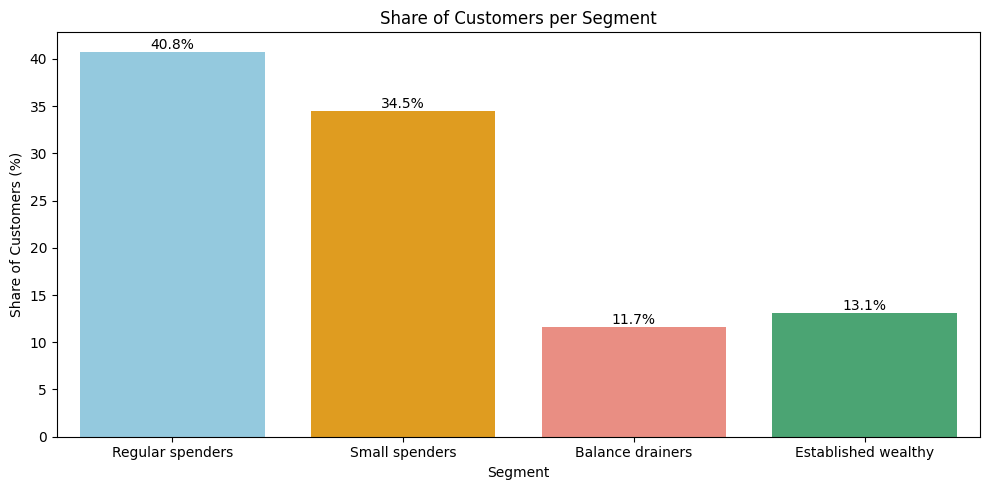

In [38]:
segment_sizes = customers["Segment"].value_counts(normalize=True).reindex(SEGMENT_ORDER) * 100

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=segment_sizes.index,
    y=segment_sizes.values,
    hue=segment_sizes.index,
    palette=CLUSTER_COLORS,
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("Share of Customers per Segment")
plt.xlabel("Segment")
plt.ylabel("Share of Customers (%)")
plt.tight_layout()
plt.show()

### Visualising the Clusters

- The model uses 4 features, so the clusters can't be drawn directly. PCA compresses the 4 scaled features into 2 components for plotting.
- Only a 20k customer sample is plotted, otherwise ~840k points hide each other.

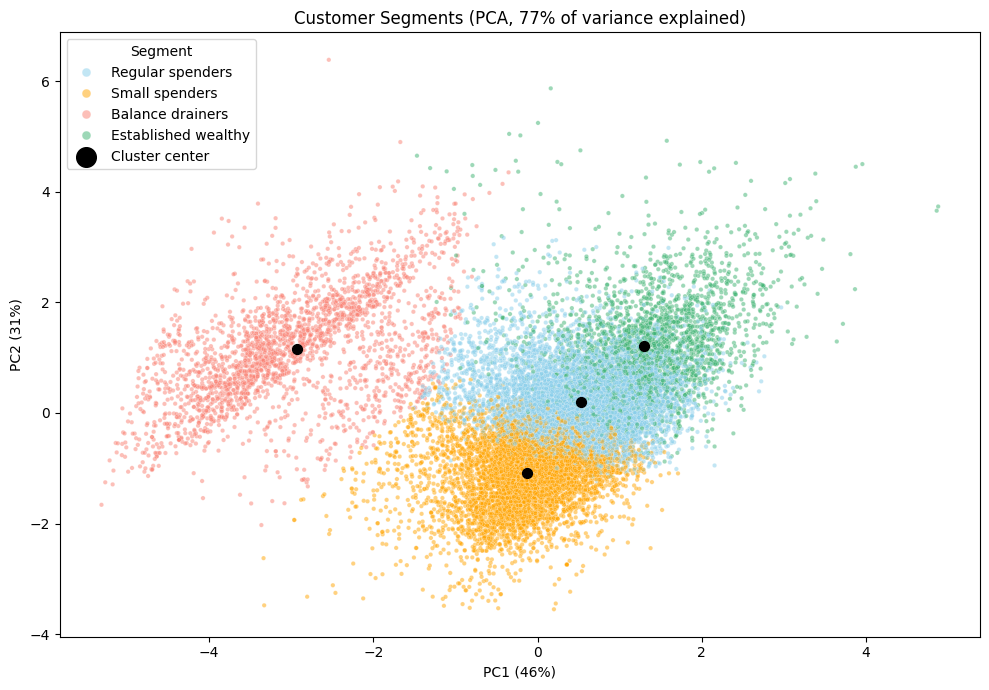

In [44]:
from sklearn.decomposition import PCA

plot_sample = X_scaled.sample(20000, random_state=42)

pca = PCA(n_components=2, random_state=42)
components = pca.fit_transform(plot_sample)

pca_df = pd.DataFrame(components, columns=["PC1", "PC2"], index=plot_sample.index)
pca_df["Segment"] = customers.loc[plot_sample.index, "Segment"]

# cluster centers projected into the same 2D space
centers_2d = pca.transform(pd.DataFrame(model.cluster_centers_, columns=FEATURES))

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Segment",
    hue_order=SEGMENT_ORDER,
    palette=CLUSTER_COLORS,
    alpha=0.5,
    s=10,
)
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker=".", s=200, label="Cluster center")

explained = pca.explained_variance_ratio_.sum() * 100
plt.title(f"Customer Segments (PCA, {explained:.0f}% of variance explained)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.0f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.0f}%)")
plt.legend(title="Segment", markerscale=2)
plt.tight_layout()
plt.show()

- PCA axes are hard to interpret, so the same clusters are also plotted on two real features: account balance vs total amount spent.

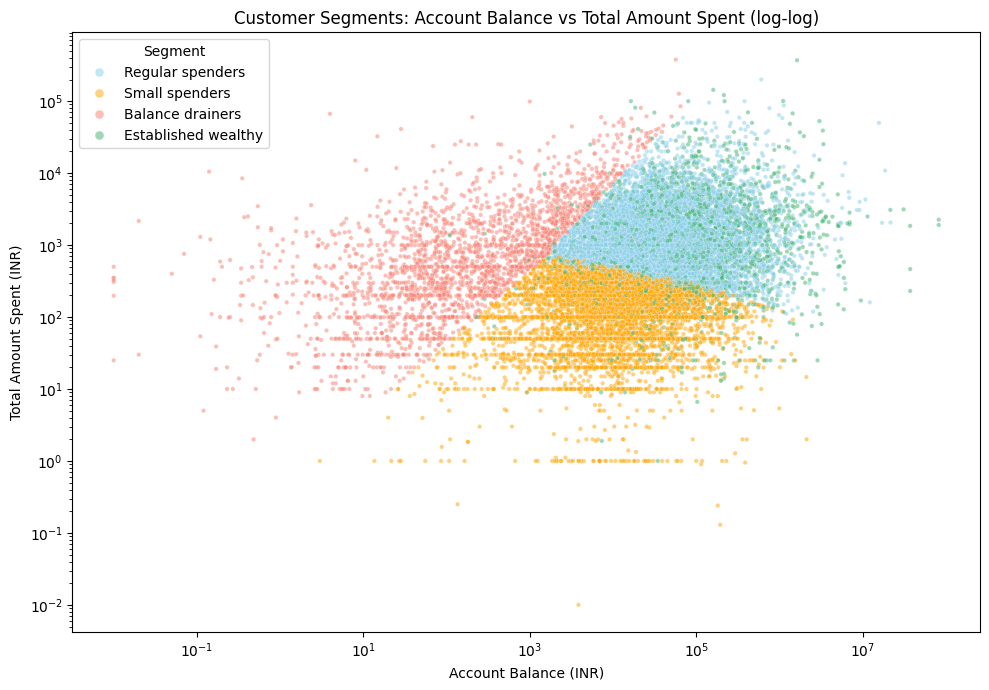

In [40]:
real_sample = customers.loc[plot_sample.index]
real_sample = real_sample[(real_sample["Account_Balance"] > 0) & (real_sample["Total_Amount"] > 0)]

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=real_sample,
    x="Account_Balance",
    y="Total_Amount",
    hue="Segment",
    hue_order=SEGMENT_ORDER,
    palette=CLUSTER_COLORS,
    alpha=0.5,
    s=10,
)
plt.xscale("log")
plt.yscale("log")

plt.title("Customer Segments: Account Balance vs Total Amount Spent (log-log)")
plt.xlabel("Account Balance (INR)")
plt.ylabel("Total Amount Spent (INR)")
plt.legend(title="Segment", markerscale=2)
plt.tight_layout()
plt.show()

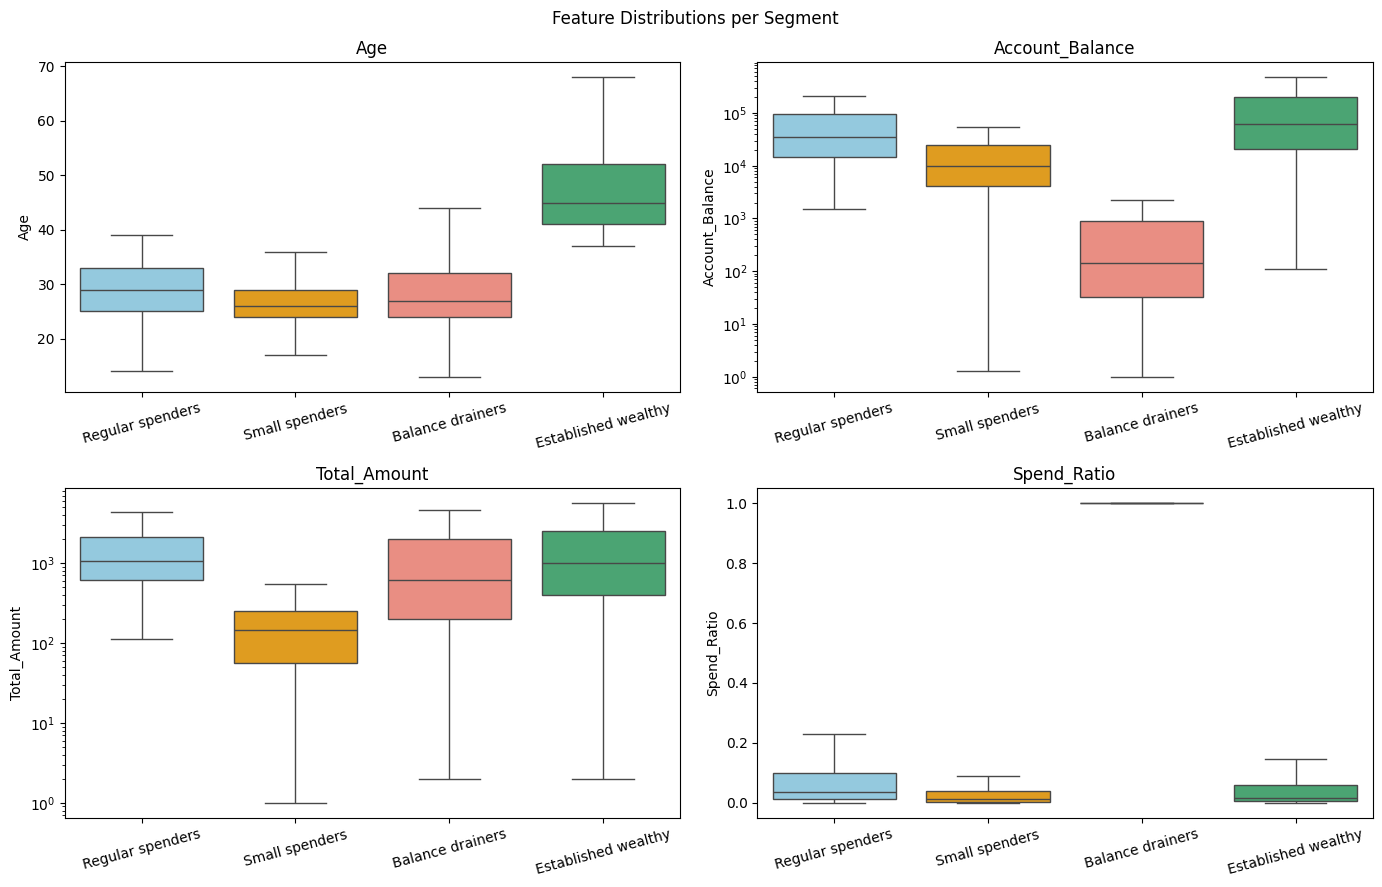

In [41]:
box_sample = customers.loc[plot_sample.index].copy()
box_sample[["Account_Balance", "Total_Amount"]] = box_sample[["Account_Balance", "Total_Amount"]] + 1  # +1 so zeros fit on a log scale

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(
        data=box_sample,
        x="Segment",
        y=col,
        hue="Segment",
        order=SEGMENT_ORDER,
        palette=CLUSTER_COLORS,
        showfliers=False,
        ax=ax,
    )
    if col in ["Account_Balance", "Total_Amount"]:
        ax.set_yscale("log")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Feature Distributions per Segment")
plt.tight_layout()
plt.show()

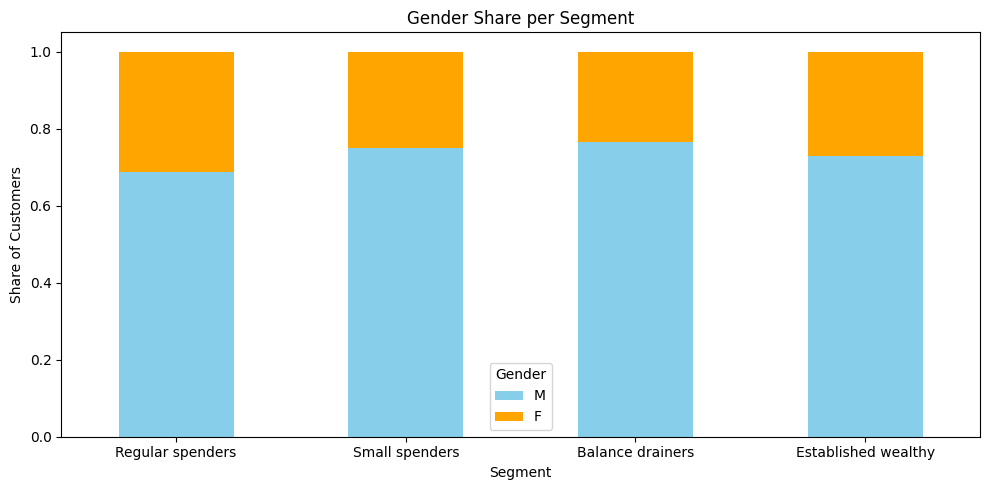

In [42]:
gender_by_segment = (
    customers.groupby("Segment")["Gender"]
      .value_counts(normalize=True)
      .unstack()
      .reindex(SEGMENT_ORDER)
      .reindex(columns=["M", "F"])
)

ax = gender_by_segment.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=["skyblue", "orange"],
)

plt.title("Gender Share per Segment")
plt.xlabel("Segment")
plt.ylabel("Share of Customers")
plt.xticks(rotation=0)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

In [43]:
# top 5 cities per segment, as share of the segment's customers
top_cities_by_segment = (
    customers.groupby("Segment")["Location"]
      .value_counts(normalize=True)
      .groupby(level=0)
      .head(5)
      .mul(100)
      .round(1)
      .rename("Share (%)")
)

top_cities_by_segment

Segment              Location 
Balance drainers     MUMBAI        8.9
                     BANGALORE     7.8
                     DELHI         7.1
                     NEW DELHI     6.6
                     GURGAON       4.7
Established wealthy  MUMBAI       11.4
                     NEW DELHI     9.0
                     GURGAON       7.9
                     BANGALORE     7.8
                     DELHI         6.4
Regular spenders     MUMBAI       11.5
                     NEW DELHI     8.6
                     BANGALORE     8.1
                     GURGAON       7.9
                     DELHI         7.0
Small spenders       MUMBAI        7.9
                     BANGALORE     7.8
                     GURGAON       6.9
                     DELHI         6.7
                     NEW DELHI     6.6
Name: Share (%), dtype: float64

## Conclusions

| Segment | Share | Profile | Business idea |
|---|---|---|---|
| **Regular spenders** | 41% | ~29 years, ~35k balance, the highest typical spend (~1,060 INR) | Core customers: cashback and loyalty programmes |
| **Small spenders** | 34% | youngest (~26), ~10k balance, very small transactions (~145 INR) | Students or early careers: digital wallets, savings products |
| **Balance drainers** | 12% | ~27 years, almost empty account (~160 INR), spend their whole balance | Financially stretched: overdraft or micro-credit offers, risk monitoring |
| **Established wealthy** | 13% | ~45 years, the highest balance (~59k), moderate spend | Investment, insurance and premium products |

- Gender doesn't separate the segments: every segment is ~70–75% male, the same as the whole dataset.
- Location doesn't either: Mumbai, New Delhi, Bangalore, Gurgaon and Delhi are the top cities in every segment.
- So the segments are driven by `age, wealth and spending behaviour`, not by who or where the customers are.

- Model testing on new data

In [45]:
def predict_segment(new_customers: pd.DataFrame) -> pd.Series:
    """Predict the segment for customers with columns Age, Account_Balance, Total_Amount."""
    X_new = new_customers.copy()

    # 1. same feature engineering as in training
    X_new["Spend_Ratio"] = (X_new["Total_Amount"] / (X_new["Account_Balance"] + 1)).clip(upper=1)
    X_new = X_new[FEATURES]

    # 2. same log transform
    X_new[["Account_Balance", "Total_Amount"]] = np.log1p(X_new[["Account_Balance", "Total_Amount"]])

    # 3. same scaling: transform only, never fit again
    X_new_scaled = pd.DataFrame(scaler.transform(X_new), columns=FEATURES, index=X_new.index)

    # 4. predict the cluster and map it to the segment name
    clusters = model.predict(X_new_scaled)
    return pd.Series(clusters, index=X_new.index).map(SEGMENT_NAMES)


In [46]:
new_customers = pd.DataFrame({
    "Age":             [22,     30,    50,     28],
    "Account_Balance": [5000,   40000, 150000, 100],
    "Total_Amount":    [80,     1500,  1200,   600],
}, index=["Student", "Young professional", "Senior", "Broke"])

predict_segment(new_customers)


Student                    Small spenders
Young professional       Regular spenders
Senior                Established wealthy
Broke                    Balance drainers
dtype: str